# Taller de movilidad urbana: taxis y clima en Nueva York

**Caso de estudio:** viajes de NYC TLC Yellow Taxi durante enero de 2024.

En este taller construiremos un flujo reproducible: adquisición, inspección, auditoría de calidad, enriquecimiento por zonas, agregación temporal, integración con clima y análisis exploratorio. No buscamos demostrar causalidad, sino aprender a formular y comprobar preguntas con datos reales.

## Objetivos

Al finalizar podrás:

- construir y validar una URL de datos abiertos;
- inspeccionar estructura, tipos y faltantes antes de analizar;
- convertir reglas de calidad en una tabla de auditoría;
- enriquecer viajes mediante uniones `many_to_one`;
- agregar pickups por zona y hora sin sesgar la serie temporal;
- convertir observaciones meteorológicas de UTC a `America/New_York`;
- comunicar patrones y límites de un análisis exploratorio.

> **Pregunta guía:** ¿cómo varían los pickups de Yellow Taxi por lugar y hora, y qué relación exploratoria muestran con temperatura y precipitación?

## Ficha de fuentes

| Fuente | Recurso usado | Papel en el taller |
|---|---|---|
| [NYC TLC Trip Record Data](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page) | Yellow Taxi, enero de 2024 (`yellow_tripdata_2024-01.parquet`) | fecha/hora, zonas, distancia, pasajeros e importes de viajes reportados |
| NYC TLC | [Taxi Zone Lookup](https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv) | traduce `LocationID` a borough, zona y `service_zone` |
| NYC TLC | [Taxi Zone Shapefile](https://d37ci6vzurychx.cloudfront.net/misc/taxi_zones.zip) | geometrías para la extensión espacial opcional |
| [NOAA GHCNh](https://www.ncei.noaa.gov/products/global-historical-climatology-network-hourly) | estación `USW00094728`, año 2024 | observaciones de clima con marcas temporales UTC |

**Periodo común:** enero de 2024 en hora local de Nueva York. Los archivos se leen desde sus URL o desde un directorio temporal; este notebook no guarda datasets en el repositorio. Consulta la documentación y licencias de cada proveedor antes de reutilizar los datos.

## 1. Preparación y modo de ejecución

En Colab normalmente basta con ejecutar los imports. Si falta el motor Parquet, descomenta la instalación. La extensión espacial se instala solo si se desea ejecutar esa sección.

In [1]:
# Instalación opcional para Google Colab/Jupyter (descomentar si hace falta):
# %pip install -q pyarrow
# %pip install -q geopandas folium requests

from io import StringIO
import tempfile
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 50)
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
# True: primera semana de enero; False: todo enero. No hay muestreo aleatorio.
MODO_CLASE = False
INICIO_MES = pd.Timestamp("2024-01-01")
FIN_MES = pd.Timestamp("2024-02-01")
FIN_ANALISIS = pd.Timestamp("2024-01-08") if MODO_CLASE else FIN_MES
ZONA_HORARIA = "America/New_York"

print(f"Ventana: {INICIO_MES} hasta {FIN_ANALISIS} (fin no incluido)")

Ventana: 2024-01-01 00:00:00 hasta 2024-02-01 00:00:00 (fin no incluido)


`MODO_CLASE` limita la lectura mediante un filtro temporal de Parquet cuando el motor lo permite. La selección es una semana completa y determinista, no una muestra aleatoria: así preservamos horas consecutivas y el flujo de agregación. En modo completo, la misma lógica procesa todo enero.

## 2. URL validada y carga reproducible

In [3]:
def construir_url_tlc(tipo, anio, mes):
    """Construye una URL TLC válida para un tipo, año y mes."""
    prefijos = {
        "yellow": "yellow_tripdata",
        "green": "green_tripdata",
        "fhv": "fhv_tripdata",
        "fhvhv": "fhvhv_tripdata",
    }
    if tipo not in prefijos:
        opciones = ", ".join(prefijos)
        raise ValueError(f"tipo debe ser uno de: {opciones}")
    if isinstance(anio, bool) or not isinstance(anio, (int, np.integer)) or not 2009 <= anio <= 2100:
        raise ValueError("anio debe ser un entero entre 2009 y 2100")
    if isinstance(mes, bool) or not isinstance(mes, (int, np.integer)) or not 1 <= mes <= 12:
        raise ValueError("mes debe ser un entero entre 1 y 12")
    archivo = f"{prefijos[tipo]}_{anio}-{mes:02d}.parquet"
    return f"https://d37ci6vzurychx.cloudfront.net/trip-data/{archivo}"

URL_VIAJES = construir_url_tlc("yellow", 2024, 1)
URL_ZONAS = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"
URL_GEOMETRIAS = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zones.zip"
URL_CLIMA = (
    "https://www.ncei.noaa.gov/oa/global-historical-climatology-network/"
    "hourly/access/by-year/2024/psv/GHCNh_USW00094728_2024.psv"
)
print(URL_VIAJES)

https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet


In [4]:
COLUMNAS_VIAJES = [
    "tpep_pickup_datetime", "tpep_dropoff_datetime",
    "passenger_count", "trip_distance", "PULocationID",
    "DOLocationID", "fare_amount", "total_amount",
]
filtros = [
    ("tpep_pickup_datetime", ">=", INICIO_MES.to_pydatetime()),
    ("tpep_pickup_datetime", "<", FIN_ANALISIS.to_pydatetime()),
]

# PyArrow aplica el filtro por fecha al leer los grupos de filas compatibles.
viajes_originales = pd.read_parquet(
    URL_VIAJES, columns=COLUMNAS_VIAJES, filters=filtros, engine="pyarrow"
)
print(f"Viajes cargados: {len(viajes_originales):,}")

Viajes cargados: 2,964,606


### Pregunta breve

¿Por qué una semana consecutiva es preferible a una muestra aleatoria si queremos comparar horas y días? Escribe una hipótesis antes de continuar.

<details><summary>Ver respuesta orientativa</summary>Una muestra aleatoria puede dejar horas incompletas y alterar sus conteos. Una ventana consecutiva conserva el orden, los ciclos diarios y el denominador temporal, aunque no necesariamente representa el mes completo.</details>

## 3. Inspección antes de limpiar

No debemos decidir reglas sin conocer el esquema. Observa dimensiones, ejemplos, tipos y faltantes.

In [5]:
print("Shape:", viajes_originales.shape)
display(viajes_originales.head())
print("\nInfo:")
viajes_originales.info()
print("\nTipos:")
display(viajes_originales.dtypes.rename("dtype").to_frame())

faltantes = (
    viajes_originales.isna().sum().rename("n_faltantes").to_frame()
    .assign(porcentaje=lambda x: 100 * x["n_faltantes"] / len(viajes_originales))
    .sort_values("porcentaje", ascending=False)
)
display(faltantes)

Shape: (2964606, 8)


,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,fare_amount,total_amount
0,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,186,79,17.7,22.70
1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,140,236,10.0,18.75
2,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,236,79,23.3,31.30
3,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,79,211,10.0,17.00
4,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,211,148,7.9,16.10



Info:
<class 'pandas.DataFrame'>
RangeIndex: 2964606 entries, 0 to 2964605
Data columns (total 8 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   tpep_pickup_datetime   datetime64[us]
 1   tpep_dropoff_datetime  datetime64[us]
 2   passenger_count        float64       
 3   trip_distance          float64       
 4   PULocationID           int32         
 5   DOLocationID           int32         
 6   fare_amount            float64       
 7   total_amount           float64       
dtypes: datetime64[us](2), float64(4), int32(2)
memory usage: 158.3 MB

Tipos:


,dtype
tpep_pickup_datetime,datetime64[us]
tpep_dropoff_datetime,datetime64[us]
passenger_count,float64
trip_distance,float64
PULocationID,int32
DOLocationID,int32
fare_amount,float64
total_amount,float64


,n_faltantes,porcentaje
passenger_count,140162,4.727846
tpep_pickup_datetime,0,0.000000
tpep_dropoff_datetime,0,0.000000
trip_distance,0,0.000000
PULocationID,0,0.000000
DOLocationID,0,0.000000
fare_amount,0,0.000000
total_amount,0,0.000000


**Observa:** `passenger_count` puede faltar por la forma de reporte. Su ausencia se conserva y no invalida automáticamente un viaje. Solo marcaremos como problemáticos los valores presentes fuera de un intervalo operativo razonable.

## 4. Calidad y auditoría

Las reglas siguientes son criterios analíticos, no verdades universales. Distancia máxima de 100 millas, hasta 8 pasajeros e importes menores a USD 1,000 son umbrales conservadores para detectar registros extremos o inválidos. Cada regla queda en una columna booleana.

In [6]:
calidad = viajes_originales.copy()
calidad["duracion_min"] = (
    calidad["tpep_dropoff_datetime"] - calidad["tpep_pickup_datetime"]
).dt.total_seconds() / 60

calidad["ok_pickup"] = calidad["tpep_pickup_datetime"].notna() & calidad["tpep_pickup_datetime"].between(INICIO_MES, FIN_ANALISIS, inclusive="left")
calidad["ok_dropoff"] = calidad["tpep_dropoff_datetime"].notna()
calidad["ok_duracion"] = calidad["duracion_min"].gt(0) & calidad["duracion_min"].le(24 * 60)
calidad["ok_distancia"] = calidad["trip_distance"].between(0, 100, inclusive="both")
calidad["ok_id_pickup_presente"] = calidad["PULocationID"].notna()
calidad["ok_id_dropoff_presente"] = calidad["DOLocationID"].notna()
calidad["ok_importes"] = (
    calidad["fare_amount"].between(0, 1_000, inclusive="both")
    & calidad["total_amount"].between(0, 1_000, inclusive="both")
    & calidad["total_amount"].ge(calidad["fare_amount"])
)
calidad["ok_pasajeros"] = calidad["passenger_count"].isna() | calidad["passenger_count"].between(0, 8, inclusive="both")

REGLAS = [c for c in calidad.columns if c.startswith("ok_")]
calidad["registro_valido"] = calidad[REGLAS].all(axis=1)
auditoria = pd.DataFrame({
    "regla": REGLAS,
    "cumplen": [int(calidad[c].sum()) for c in REGLAS],
    "incumplen": [int((~calidad[c]).sum()) for c in REGLAS],
})
auditoria["porcentaje_incumple"] = 100 * auditoria["incumplen"] / len(calidad)
display(auditoria.sort_values("porcentaje_incumple", ascending=False))

,regla,cumplen,incumplen,porcentaje_incumple
6,ok_importes,2927032,37574,1.267420
2,ok_duracion,2963720,886,0.029886
3,ok_distancia,2964547,59,0.001990
7,ok_pasajeros,2964605,1,0.000034
0,ok_pickup,2964606,0,0.000000
1,ok_dropoff,2964606,0,0.000000
5,ok_id_dropoff_presente,2964606,0,0.000000
4,ok_id_pickup_presente,2964606,0,0.000000


In [7]:
# Se mantienen por separado para no borrar silenciosamente información.
viajes_rechazados = calidad.loc[~calidad["registro_valido"]].copy()
viajes_validos = calidad.loc[calidad["registro_valido"]].copy()
print(f"Válidos: {len(viajes_validos):,} | Rechazados: {len(viajes_rechazados):,}")
display(viajes_rechazados[COLUMNAS_VIAJES + ["duracion_min"] + REGLAS].head())

Válidos: 2,926,101 | Rechazados: 38,505


,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,fare_amount,total_amount,duracion_min,ok_pickup,ok_dropoff,ok_duracion,ok_distancia,ok_id_pickup_presente,ok_id_dropoff_presente,ok_importes,ok_pasajeros
23,2024-01-01 00:14:29,2024-01-01 00:14:29,1.0,0.00,236,264,3.0,8.00,0.000000,True,True,False,True,True,True,True,True
99,2024-01-01 00:18:24,2024-01-01 00:30:39,1.0,2.16,249,232,-13.5,-18.50,12.250000,True,True,True,True,True,True,False,True
504,2024-01-01 00:04:00,2024-01-01 00:04:44,1.0,0.01,63,63,-31.5,-34.25,0.733333,True,True,True,True,True,True,False,True
534,2024-01-01 00:41:42,2024-01-01 00:46:00,1.0,0.47,249,113,-5.8,-10.80,4.300000,True,True,True,True,True,True,False,True
550,2024-01-01 00:42:02,2024-01-01 01:14:33,1.0,5.48,107,61,-33.1,-38.10,32.516667,True,True,True,True,True,True,False,True


### Ejercicio 1: sensibilidad de una regla

Calcula cuántos viajes quedarían fuera si la distancia máxima fuese 50 millas, sin modificar `viajes_validos`.

In [8]:
# Tu respuesta:
# fuera_con_umbral_50 = ...

<details><summary>Ver solución</summary>

```python
fuera_con_umbral_50 = (~calidad["trip_distance"].between(0, 50)).sum()
print(fuera_con_umbral_50)
```

Conviene comparar este resultado con `ok_distancia` y justificar el umbral con conocimiento del dominio.
</details>

## 5. Enriquecimiento con zonas

### Objetivo

La tabla de viajes identifica el origen mediante `PULocationID` y el destino mediante `DOLocationID`. Estos códigos son útiles para relacionar tablas, pero no permiten interpretar directamente dónde comenzó o terminó un viaje.

En esta sección agregaremos a cada viaje el nombre de la zona, el borough y la clasificación de servicio tanto del origen como del destino. Conceptualmente:

```text
PULocationID = 161
        ↓
pickup_zone = Midtown Center
pickup_borough = Manhattan
pickup_service_zone = Yellow Zone
```

El enriquecimiento no cambia la unidad de observación: cada fila continúa representando un viaje Yellow Taxi reportado. Solo agrega contexto geográfico a sus identificadores.

### 5.1. El catálogo de zonas

`taxi_zone_lookup.csv` es un **catálogo de correspondencias** publicado por NYC TLC. No contiene viajes: contiene una descripción por `LocationID`.

| Columna | Significado |
|---|---|
| `LocationID` | Identificador numérico de la zona TLC |
| `Borough` | Distrito amplio, como Manhattan, Queens o Brooklyn |
| `Zone` | Nombre específico de la zona TLC |
| `service_zone` | Clasificación operativa, como `Yellow Zone`, `Boro Zone` o `Airports` |

Para que el catálogo pueda representar el lado **uno** de una unión, `LocationID` debe ser único.

In [9]:
zonas = pd.read_csv(URL_ZONAS)
display(zonas.head())
print("Cantidad de zonas:", len(zonas))
print("LocationID es único:", zonas["LocationID"].is_unique)

if zonas["LocationID"].duplicated().any():
    raise ValueError("Taxi Zone Lookup contiene LocationID duplicados")

,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


Cantidad de zonas: 265
LocationID es único: True


### 5.2. Un catálogo, dos roles

Cada viaje consulta el mismo catálogo desde dos papeles diferentes:

```text
PULocationID → zona de origen o pickup
DOLocationID → zona de destino o dropoff
```

Por eso creamos `zonas_pickup` y `zonas_dropoff`. No son dos catálogos distintos ni duplican los viajes: son dos versiones del mismo catálogo con nombres que explicitan el rol de sus columnas.

| Origen | Destino |
|---|---|
| `pickup_zone` | `dropoff_zone` |
| `pickup_borough` | `dropoff_borough` |
| `pickup_service_zone` | `dropoff_service_zone` |

Renombrar antes de unir evita nombres ambiguos como `Zone_x` y `Zone_y`. `DataFrame.rename()` devuelve estas versiones adaptadas sin modificar `zonas`.

In [10]:
zonas_pickup = zonas.rename(columns={
    "LocationID": "PULocationID", "Borough": "pickup_borough",
    "Zone": "pickup_zone", "service_zone": "pickup_service_zone",
})
zonas_dropoff = zonas.rename(columns={
    "LocationID": "DOLocationID", "Borough": "dropoff_borough",
    "Zone": "dropoff_zone", "service_zone": "dropoff_service_zone",
})

display(zonas_pickup.head(2))
display(zonas_dropoff.head(2))

,PULocationID,pickup_borough,pickup_zone,pickup_service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone


,DOLocationID,dropoff_borough,dropoff_zone,dropoff_service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone


### 5.3. Cardinalidad `many_to_one`

La relación esperada es **muchos viajes → una descripción de zona**. Un mismo `PULocationID` o `DOLocationID` puede aparecer en miles de viajes, pero cada identificador debe aparecer como máximo una vez en el catálogo correspondiente.

`validate="many_to_one"` hace que pandas compruebe esta condición durante la unión. Si el catálogo tuviera dos filas para `LocationID = 161`, tres viajes con ese identificador producirían seis filas:

```text
3 viajes × 2 coincidencias en el catálogo = 6 filas
```

Esa multiplicación inflaría conteos, importes, promedios y mapas. La validación detiene el proceso con un error en lugar de producir silenciosamente un resultado incorrecto. También ayuda a detectar catálogos repetidos, mezcla de versiones o descripciones contradictorias para un mismo ID.

### 5.4. Dos uniones izquierdas

Primero agregamos los atributos del origen y después los del destino. `how="left"` conserva todos los viajes válidos. Si un ID no aparece en el catálogo, el viaje permanece y sus atributos geográficos quedan como `NaN`, lo que permite auditar la falta de correspondencia en vez de eliminarla silenciosamente.

In [11]:
viajes_zonas = (
    viajes_validos.merge(zonas_pickup, on="PULocationID", how="left", validate="many_to_one")
    .merge(zonas_dropoff, on="DOLocationID", how="left", validate="many_to_one")
)

### 5.5. Controles posteriores e interpretación

Después de unir comprobamos dos propiedades diferentes:

1. **Conservación de filas:** la cantidad de viajes no debe cambiar.
2. **Cobertura del catálogo:** contamos los viajes cuyo ID no encontró nombre de zona.

`many_to_one` no garantiza cobertura completa ni detecta viajes duplicados, IDs faltantes, nombres incorrectos en una fila única o el uso de la clave equivocada. Por eso se complementa con estos controles y con la revisión semántica de las columnas obtenidas.

In [12]:
assert len(viajes_zonas) == len(viajes_validos), "La unión cambió el número de viajes"

sin_nombre_pickup = viajes_zonas["pickup_zone"].isna().sum()
sin_nombre_dropoff = viajes_zonas["dropoff_zone"].isna().sum()
print("Viajes antes y después:", len(viajes_validos), len(viajes_zonas))
print("Sin zona pickup:", sin_nombre_pickup, "| Sin zona dropoff:", sin_nombre_dropoff)

COLUMNAS_ZONA = [
    "PULocationID", "pickup_borough", "pickup_zone", "pickup_service_zone",
    "DOLocationID", "dropoff_borough", "dropoff_zone", "dropoff_service_zone",
]
display(viajes_zonas[COLUMNAS_ZONA].head())

Viajes antes y después: 2926101 2926101
Sin zona pickup: 10177 | Sin zona dropoff: 15295


,PULocationID,pickup_borough,pickup_zone,pickup_service_zone,DOLocationID,dropoff_borough,dropoff_zone,dropoff_service_zone
0,186,Manhattan,Penn Station/Madison Sq West,Yellow Zone,79,Manhattan,East Village,Yellow Zone
1,140,Manhattan,Lenox Hill East,Yellow Zone,236,Manhattan,Upper East Side North,Yellow Zone
2,236,Manhattan,Upper East Side North,Yellow Zone,79,Manhattan,East Village,Yellow Zone
3,79,Manhattan,East Village,Yellow Zone,211,Manhattan,SoHo,Yellow Zone
4,211,Manhattan,SoHo,Yellow Zone,148,Manhattan,Lower East Side,Yellow Zone


### Resultado de la sección

Cada fila sigue representando un viaje, pero ahora permite interpretar tanto su origen como su destino. Las zonas son áreas geográficas agregadas definidas por TLC: no indican una dirección ni una coordenada exacta, y el enriquecimiento no agrega demanda total, solicitudes no atendidas ni vehículos disponibles.

### Pregunta breve

¿Qué ocurriría si `LocationID = 161` apareciera dos veces en el catálogo y no utilizáramos `validate="many_to_one"`?

<details><summary>Ver respuesta orientativa</summary>Cada viaje con ese identificador encontraría dos coincidencias y aparecería dos veces en el resultado. Los conteos y agregaciones posteriores quedarían inflados. Con `validate="many_to_one"`, pandas detecta que el lado del catálogo no es único y detiene la unión.</details>

## 6. Agregación zona-hora de pickups

Los timestamps TLC se interpretan como hora local. En enero de 2024 no hay transición de horario de verano, pero explicitar la zona horaria evita una unión ambigua con NOAA.

In [13]:
viajes_zonas["pickup_hora"] = (
    viajes_zonas["tpep_pickup_datetime"]
    .dt.tz_localize(ZONA_HORARIA, ambiguous="raise", nonexistent="raise")
    .dt.floor("h")
)
pickups_zona_hora = (
    viajes_zonas.groupby(
        ["pickup_hora", "PULocationID", "pickup_borough", "pickup_zone"],
        observed=True, dropna=False,
    )
    .size().rename("pickups").reset_index()
)
assert pickups_zona_hora.duplicated(["pickup_hora", "PULocationID"]).sum() == 0
display(pickups_zona_hora.head())

,pickup_hora,PULocationID,pickup_borough,pickup_zone,pickups
0,2024-01-01 00:00:00-05:00,4,Manhattan,Alphabet City,24
1,2024-01-01 00:00:00-05:00,7,Queens,Astoria,4
2,2024-01-01 00:00:00-05:00,9,Queens,Auburndale,1
3,2024-01-01 00:00:00-05:00,10,Queens,Baisley Park,6
4,2024-01-01 00:00:00-05:00,12,Manhattan,Battery Park,4


## 7. Clima: UTC, hora local y resumen horario

GHCNh puede contener varias observaciones dentro de una hora. Seleccionaremos variables numéricas, convertiremos valores no numéricos a faltantes y resumiremos a una fila por hora. Temperatura usa media; precipitación usa suma con `min_count=1` para no convertir una hora totalmente faltante en cero.

In [14]:
COLUMNAS_CLIMA = [
    "STATION", "Station_name", "DATE", "temperature",
    "relative_humidity", "wind_speed", "precipitation", "visibility",
]
with urlopen(URL_CLIMA) as respuesta:
    texto_clima = respuesta.read().decode("utf-8")
clima_bruto = pd.read_csv(StringIO(texto_clima), sep="|", usecols=COLUMNAS_CLIMA, low_memory=False)
assert clima_bruto["STATION"].astype(str).eq("USW00094728").all()
print("Observaciones meteorológicas cargadas:", len(clima_bruto))

Observaciones meteorológicas cargadas: 11222


In [15]:
clima = clima_bruto.copy()
clima["fecha_utc"] = pd.to_datetime(clima["DATE"], utc=True, errors="coerce")
clima["fecha_ny"] = clima["fecha_utc"].dt.tz_convert(ZONA_HORARIA)
inicio_local = INICIO_MES.tz_localize(ZONA_HORARIA)
fin_local = FIN_ANALISIS.tz_localize(ZONA_HORARIA)
clima = clima.loc[clima["fecha_ny"].between(inicio_local, fin_local, inclusive="left")].copy()

VARIABLES_CLIMA = ["temperature", "relative_humidity", "wind_speed", "precipitation", "visibility"]
clima[VARIABLES_CLIMA] = clima[VARIABLES_CLIMA].apply(pd.to_numeric, errors="coerce")
clima["hora"] = clima["fecha_ny"].dt.floor("h")
clima_horario = (
    clima.groupby("hora", as_index=False)
    .agg(
        temperatura_c=("temperature", "mean"),
        humedad_relativa=("relative_humidity", "mean"),
        viento=("wind_speed", "mean"),
        precipitacion_mm=("precipitation", lambda s: s.sum(min_count=1)),
        visibilidad=("visibility", "mean"),
        observaciones=("fecha_ny", "size"),
    )
)
if clima_horario["hora"].duplicated().any():
    raise ValueError("El resumen climático no es único por hora")
display(clima_horario.head())

,hora,temperatura_c,humedad_relativa,viento,precipitacion_mm,visibilidad,observaciones
0,2024-01-01 00:00:00-05:00,5.6,55.0,3.1,0.0,16.093,1
1,2024-01-01 01:00:00-05:00,5.6,58.0,2.1,0.0,16.093,1
2,2024-01-01 02:00:00-05:00,5.0,60.0,0.0,0.0,16.093,1
3,2024-01-01 03:00:00-05:00,5.0,62.0,1.5,0.0,16.093,1
4,2024-01-01 04:00:00-05:00,4.4,68.0,0.0,0.0,16.093,1


### Ejercicio 2: cobertura temporal

Compara las horas esperadas de la ventana con las horas observadas en `clima_horario`. ¿Hay huecos?

In [16]:
# Tu respuesta:
# horas_esperadas = ...
# horas_sin_clima = ...

<details><summary>Ver solución</summary>

```python
horas_esperadas = pd.date_range(inicio_local, fin_local, freq="h", inclusive="left")
horas_sin_clima = horas_esperadas.difference(clima_horario["hora"])
print("Horas esperadas:", len(horas_esperadas))
print("Horas sin observación:", len(horas_sin_clima))
display(horas_sin_clima[:10])
```
</details>

## 8. Unión zona-hora con clima

Cada fila zona-hora debe encontrar como máximo una fila climática. La unión izquierda conserva los pickups aunque el clima falte.

In [17]:
zona_hora_clima = pickups_zona_hora.merge(
    clima_horario, left_on="pickup_hora", right_on="hora",
    how="left", validate="many_to_one", indicator=True,
)
assert len(zona_hora_clima) == len(pickups_zona_hora), "La unión alteró la cardinalidad izquierda"
auditoria_union = zona_hora_clima["_merge"].value_counts(dropna=False).rename_axis("resultado").to_frame("filas")
display(auditoria_union)
zona_hora_clima = zona_hora_clima.drop(columns="_merge")

,filas
resultado,
both,77335
left_only,131
right_only,0


### ¿Por qué el clima queda repetido por zona?

La unidad de `zona_hora_clima` es **una zona en una hora**. En cambio, `clima_horario` contiene una sola observación por hora. Cuando esa observación se une con varias zonas de la misma hora, pandas la copia en cada fila zona-hora.

Ejemplo conceptual:

| zona | hora | pickups | temperatura |
|---|---|---:|---:|
| A | 08:00 | 20 | 5 °C |
| B | 08:00 | 35 | 5 °C |
| C | 08:00 | 15 | 5 °C |

Los tres valores de `5 °C` no son mediciones diferentes: son la misma observación meteorológica replicada por la unión `many_to_one`. Esta repetición es intencional, no un duplicado accidental. Además, NOAA representa una estación meteorológica; no estamos estimando un clima diferente para cada zona.

## 9. Análisis exploratorio con pandas y matplotlib

Lee cada gráfico como evidencia descriptiva. Pregunta siempre: ¿qué unidad representa?, ¿qué filtros se aplicaron?, ¿qué explicación alternativa existe?

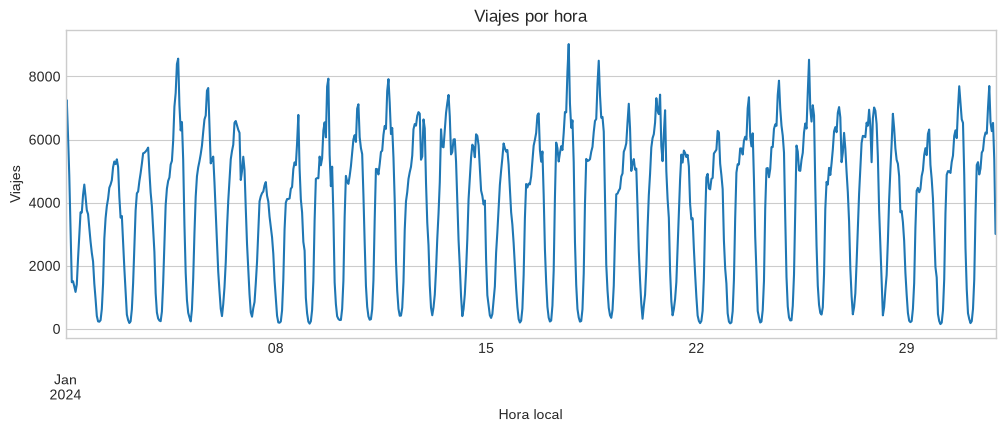

In [18]:
viajes_por_hora = viajes_zonas.set_index("pickup_hora").resample("h").size()
ax = viajes_por_hora.plot(figsize=(12, 4), color="#1f77b4", linewidth=1.5)
ax.set(title="Viajes por hora", xlabel="Hora local", ylabel="Viajes")
plt.show()

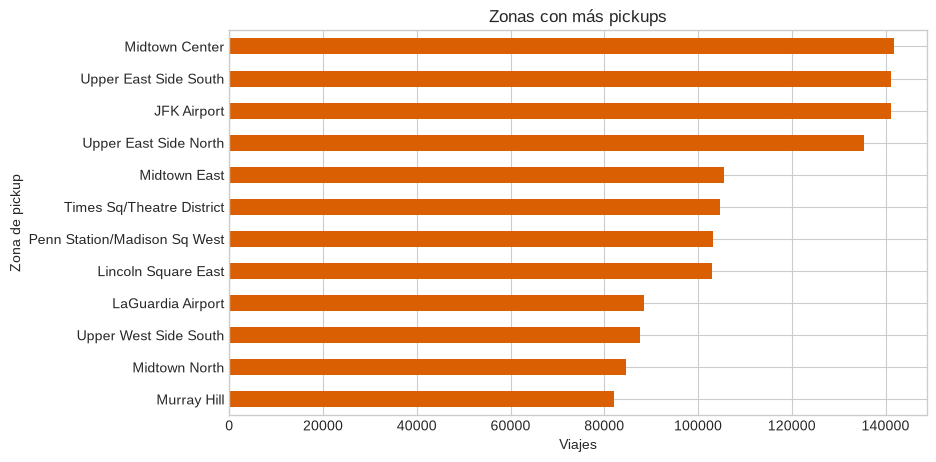

,pickups
pickup_zone,
Midtown Center,141714
Upper East Side South,141237
JFK Airport,141107
Upper East Side North,135303
Midtown East,105440
Times Sq/Theatre District,104590
Penn Station/Madison Sq West,103254
Lincoln Square East,102960
LaGuardia Airport,88556


In [19]:
top_zonas = viajes_zonas["pickup_zone"].value_counts().head(12).sort_values()
ax = top_zonas.plot.barh(figsize=(9, 5), color="#d95f02")
ax.set(title="Zonas con más pickups", xlabel="Viajes", ylabel="Zona de pickup")
plt.show()
display(top_zonas.sort_values(ascending=False).rename("pickups").to_frame())

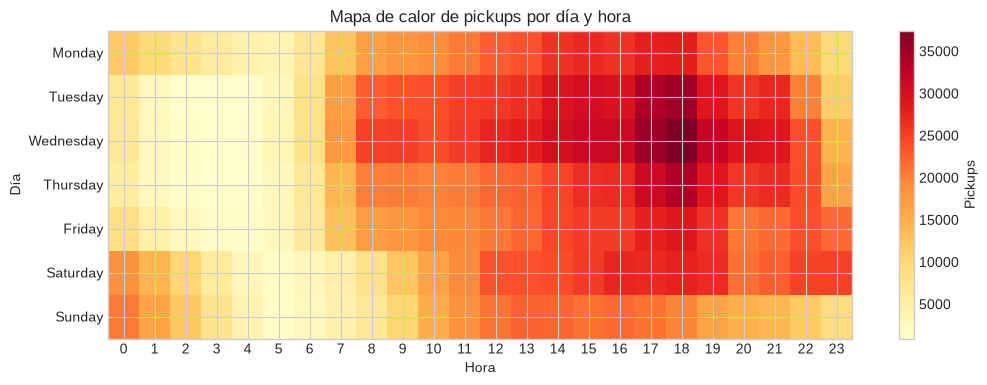

In [20]:
patron = viajes_zonas.assign(
    dia=viajes_zonas["pickup_hora"].dt.day_name(),
    hora_dia=viajes_zonas["pickup_hora"].dt.hour,
).pivot_table(index="dia", columns="hora_dia", values="PULocationID", aggfunc="size", fill_value=0)
orden_dias = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
patron = patron.reindex([d for d in orden_dias if d in patron.index])
fig, ax = plt.subplots(figsize=(12, 4))
imagen = ax.imshow(patron, aspect="auto", cmap="YlOrRd")
ax.set(title="Mapa de calor de pickups por día y hora", xlabel="Hora", ylabel="Día")
ax.set_xticks(range(24), labels=range(24))
ax.set_yticks(range(len(patron.index)), labels=patron.index)
fig.colorbar(imagen, ax=ax, label="Pickups")
plt.show()

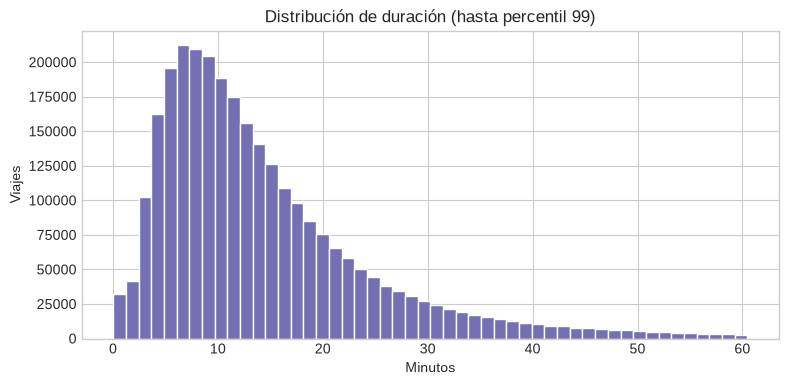

Percentil 99 mostrado: 60.5 minutos


In [21]:
limite_99 = viajes_validos["duracion_min"].quantile(0.99)
ax = viajes_validos.loc[viajes_validos["duracion_min"] <= limite_99, "duracion_min"].plot.hist(
    bins=50, figsize=(9, 4), color="#7570b3", edgecolor="white"
)
ax.set(title="Distribución de duración (hasta percentil 99)", xlabel="Minutos", ylabel="Viajes")
plt.show()
print("Percentil 99 mostrado:", round(limite_99, 1), "minutos")

### 9.1. De zona-hora a una observación por hora

Para comparar la actividad total de taxis con el clima debemos volver de la unidad **zona-hora** a la unidad **hora**. En el ejemplo anterior:

```text
pickups = 20 + 35 + 15 = 70
temperatura = 5 °C
```

Por eso usamos operaciones diferentes:

- `sum` para `pickups`, porque cada zona aporta viajes distintos;
- `first` para temperatura y precipitación, porque cada fila contiene una copia del mismo clima horario.

Sumar la temperatura produciría `5 + 5 + 5 = 15 °C`, un valor sin interpretación física. El uso de `first` requiere comprobar antes que una misma hora no contenga valores climáticos diferentes entre zonas.

Consistencia climática por hora: OK


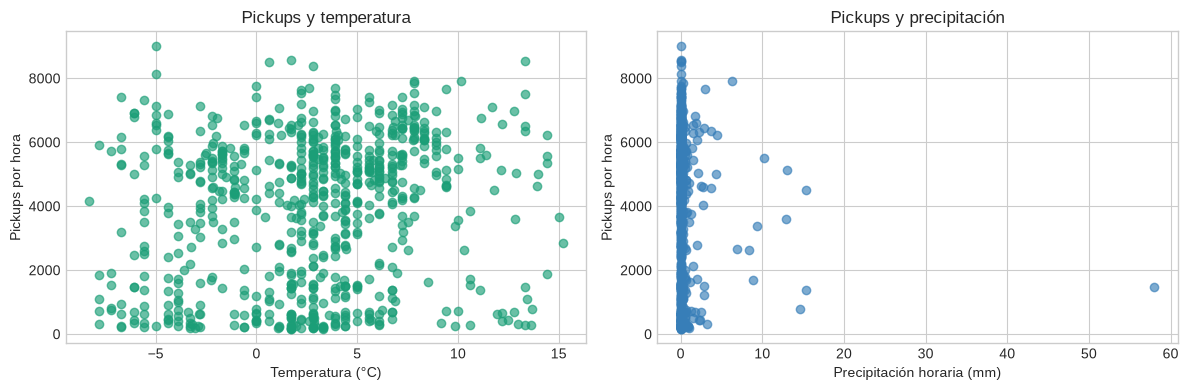

,pickups,temperatura_c,precipitacion_mm
pickups,1.000,0.158,-0.054
temperatura_c,0.158,1.000,0.193
precipitacion_mm,-0.054,0.193,1.000


In [22]:
# Verificamos el supuesto necesario para conservar una sola copia con 'first'.
variables_clima_repetidas = ["temperatura_c", "precipitacion_mm"]
consistencia_clima = (
    zona_hora_clima
    .groupby("pickup_hora")[variables_clima_repetidas]
    .nunique(dropna=False)
)
assert consistencia_clima.le(1).all().all(), (
    "Una misma hora contiene valores climáticos diferentes entre zonas"
)
print("Consistencia climática por hora: OK")

# El clima está repetido por zona; volvemos a una observación por hora.
comparacion_horaria = (
    zona_hora_clima.groupby("pickup_hora", as_index=False)
    .agg(
        pickups=("pickups", "sum"),
        temperatura_c=("temperatura_c", "first"),
        precipitacion_mm=("precipitacion_mm", "first"),
    )
)
assert not comparacion_horaria["pickup_hora"].duplicated().any()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(comparacion_horaria["temperatura_c"], comparacion_horaria["pickups"], alpha=0.65, color="#1b9e77")
axes[0].set(xlabel="Temperatura (°C)", ylabel="Pickups por hora", title="Pickups y temperatura")
axes[1].scatter(comparacion_horaria["precipitacion_mm"], comparacion_horaria["pickups"], alpha=0.65, color="#377eb8")
axes[1].set(xlabel="Precipitación horaria (mm)", ylabel="Pickups por hora", title="Pickups y precipitación")
plt.tight_layout()
plt.show()
display(comparacion_horaria[["pickups", "temperatura_c", "precipitacion_mm"]].corr().round(3))

### Pregunta breve

¿Qué ocurriría si sumáramos la temperatura después de haberla replicado por zona?

<details><summary>Ver respuesta orientativa</summary>La misma observación se contabilizaría varias veces y produciría una temperatura sin interpretación física. Los pickups sí se suman porque cada zona aporta viajes diferentes; el clima se conserva una sola vez porque es el mismo valor replicado.</details>

### Ejercicio 3: interpretar sin exagerar

Escribe dos observaciones de los gráficos y una explicación alternativa. Evita frases causales como “la lluvia provoca...”.

**Tu respuesta:**

1. ...
2. ...
3. Explicación alternativa: ...

<details><summary>Ver pauta de solución</summary>Una respuesta sólida identifica dirección, magnitud o franjas horarias, menciona la ventana analizada y reconoce factores de confusión como hora pico, día de semana, aeropuerto, feriados o disponibilidad de taxis. Una correlación horaria no permite atribuir causalidad al clima.</details>

## 10. Exportar el producto fuera del repositorio

Antes de exportar comprobamos la clave, ordenamos el producto y usamos el directorio temporal del sistema. El nombre distingue el modo de clase del mes completo para no declarar una cobertura que no fue procesada.

In [23]:
producto = zona_hora_clima.sort_values(["pickup_hora", "PULocationID"]).copy()
if producto.duplicated(["pickup_hora", "PULocationID"]).any():
    raise ValueError("La clave zona-hora no es única")

alcance = "primera_semana_enero_2024" if MODO_CLASE else "enero_2024"
ruta_producto = Path(tempfile.gettempdir()) / f"zona_hora_{alcance}.parquet"
producto.to_parquet(ruta_producto, index=False)
print("Producto temporal:", ruta_producto)
print("Unidad: zona de origen-hora local | Zona horaria:", ZONA_HORARIA)

Producto temporal: /tmp/zona_hora_enero_2024.parquet
Unidad: zona de origen-hora local | Zona horaria: America/New_York


## 11. Extensión espacial opcional

Esta celda descarga el ZIP del shapefile a un directorio temporal, extrae juntos sus componentes (`.shp`, `.dbf`, `.shx`, `.prj`) y construye un mapa Folium. La extracción explícita evita depender de que el backend geoespacial admita rutas virtuales `zip://`; al finalizar, el directorio temporal se elimina y no deja geometrías en el repositorio. Si `geopandas`, `folium` o `requests` no están instalados, informa exactamente cómo habilitar la sección y el resto del taller sigue siendo utilizable.

In [24]:
try:
    import folium
    import geopandas as gpd
    import requests
    import zipfile
except ModuleNotFoundError as error:
    print(
        f"Sección espacial omitida: falta '{error.name}'. "
        "Descomenta `%pip install -q geopandas folium requests`, reinicia si es necesario y vuelve a ejecutar."
    )
else:
    with tempfile.TemporaryDirectory() as directorio_base:
        ruta_zip = Path(directorio_base) / "taxi_zones.zip"
        respuesta = requests.get(URL_GEOMETRIAS, timeout=60)
        respuesta.raise_for_status()
        ruta_zip.write_bytes(respuesta.content)
        if not zipfile.is_zipfile(ruta_zip):
            raise zipfile.BadZipFile("La descarga de zonas TLC no es un archivo ZIP válido")

        directorio_extraido = Path(directorio_base) / "taxi_zones_extraido"
        directorio_extraido.mkdir()
        with zipfile.ZipFile(ruta_zip) as archivo_zip:
            archivo_zip.extractall(directorio_extraido)

        archivos_shp = sorted(directorio_extraido.rglob("*.shp"))
        if not archivos_shp:
            raise FileNotFoundError("No se encontró un archivo .shp dentro del ZIP de zonas TLC")
        ruta_shp = next((ruta for ruta in archivos_shp if ruta.name == "taxi_zones.shp"), archivos_shp[0])
        geo_zonas = gpd.read_file(ruta_shp).to_crs(epsg=4326)

    pickups_mapa = viajes_zonas["PULocationID"].value_counts().rename("pickups").reset_index()
    geo_zonas["LocationID"] = pd.to_numeric(geo_zonas["LocationID"])
    geo_mapa = geo_zonas.merge(pickups_mapa, left_on="LocationID", right_on="PULocationID", how="left", validate="one_to_one")
    geo_mapa["pickups"] = geo_mapa["pickups"].fillna(0)
    min_x, min_y, max_x, max_y = geo_mapa.total_bounds
    centro = [(min_y + max_y) / 2, (min_x + max_x) / 2]
    mapa = folium.Map(location=centro, zoom_start=10, tiles="CartoDB positron")
    folium.Choropleth(
        geo_data=geo_mapa, data=geo_mapa, columns=["LocationID", "pickups"],
        key_on="feature.properties.LocationID", fill_color="YlOrRd",
        fill_opacity=0.7, line_opacity=0.3, legend_name="Pickups",
    ).add_to(mapa)
    folium.GeoJson(
        geo_mapa, style_function=lambda _: {"fillOpacity": 0, "weight": 0},
        tooltip=folium.GeoJsonTooltip(fields=["zone", "borough", "pickups"], aliases=["Zona", "Borough", "Pickups"]),
    ).add_to(mapa)
    display(mapa)

Sección espacial omitida: falta 'folium'. Descomenta `%pip install -q geopandas folium requests`, reinicia si es necesario y vuelve a ejecutar.


## 12. Conclusiones y límites

**Qué construimos**

- un proceso reproducible para enero de 2024, escalable de una semana al mes;
- una auditoría que hace visibles los criterios de exclusión;
- una tabla zona-hora enriquecida con clima mediante cardinalidad comprobada;
- visualizaciones temporales, espaciales y de asociación exploratoria.

**Límites que deben acompañar cualquier conclusión**

- Los registros son **viajes reportados de Yellow Taxi**, no demanda total, viajes no atendidos ni toda la movilidad de Nueva York.
- Una sola estación, `USW00094728`, no representa toda la variación meteorológica espacial de la ciudad.
- La cobertura y frecuencia de GHCNh pueden variar; resumir precipitación subhoraria exige revisar la documentación de medición.
- Las reglas de calidad y sus umbrales afectan los resultados y deben justificarse.
- La asociación entre pickups y clima está confundida por hora, día, localización, oferta, eventos y otros factores. **Correlación no implica causalidad.**
- `MODO_CLASE=True` describe solo la primera semana; para conclusiones mensuales se debe ejecutar el mes completo y evaluar estabilidad.

**Cierre:** ¿qué dato adicional pedirías para distinguir mejor demanda, oferta y viajes efectivamente realizados?

# Trabajo práctico: exploración de dos variables

**Estudiante:** Ezequiel Zunino
**Curso:** Data Science · semana 3, clase 3 · modalidad individual
**Par elegido:** `PC-02`, `pickups` × `humedad_relativa`
**Vista analítica:** H (una fila por hora)
**Periodo:** enero de 2024 completo, `[2024-01-01, 2024-02-01)` en `America/New_York`
**Modo de ejecución:** `MODO_CLASE = False`
**Fecha de acceso a las fuentes:** 2 de noviembre de 2026

Este par y esta vista quedan registrados antes de ejecutar cualquier análisis y se mantienen durante todo el trabajo.

**Cambios sobre el notebook base:** el único cambio es `MODO_CLASE = False`. No se modificaron fuentes, periodo ni reglas de calidad. Los ejercicios opcionales del taller quedaron sin completar, porque no forman parte de esta entrega. `precipitacion_mm` no se usa en este análisis, como indica la consigna.

## 5. Definición del análisis

| Campo | Respuesta |
|---|---|
| Código y par elegido | `PC-02`: `pickups` × `humedad_relativa` |
| Pregunta exploratoria | ¿Cómo varían los pickups de Yellow Taxi por hora junto con la humedad relativa registrada en la estación Central Park durante enero de 2024, y esa asociación se sostiene al comparar horas del mismo momento del día? |
| Significado de la primera columna | `pickups`: cantidad de viajes Yellow Taxi válidos iniciados en esa hora, sumados entre todas las zonas de origen. |
| Significado de la segunda columna | `humedad_relativa`: humedad relativa en %, media de los reportes de la estación NOAA dentro de cada hora. |
| Tipo semántico de cada columna | `pickups`: conteo discreto no negativo. `humedad_relativa`: magnitud continua acotada entre 0 y 100. |
| Unidad analítica y vista | Una hora local de enero de 2024, vista H. |
| Periodo y zona horaria | `[2024-01-01, 2024-02-01)` en `America/New_York`. |
| Población registrada | Viajes Yellow Taxi realizados, reportados a TLC y aprobados por los filtros de calidad del notebook base, más las observaciones de una sola estación meteorológica. |
| Denominador o tamaño válido | 744 horas esperadas. El tamaño válido son las horas con `pickups` y `humedad_relativa` presentes, y se calcula en la vista H. |
| Afirmaciones que los datos no permiten | Que la humedad cause cambios en los pickups, que los pickups midan la demanda total o las solicitudes no atendidas, que la humedad de una estación represente a cada zona, y generalizar a otros meses o años. |

### Decisiones declaradas antes de mirar los resultados

**Casos anómalos.** Se usa la regla de Tukey sobre cada variable. Como los pickups tienen un ciclo diario, se agrega una regla complementaria para pickups: Tukey sobre el desvío respecto de la mediana de su combinación de tipo de día y hora del día. Esta segunda regla busca horas raras para su momento, que la regla global no puede ver.

**Análisis de sensibilidad.** Se definen estas tres alternativas, y se informan todas sin importar cuál dé el resultado más llamativo:

1. Pearson frente a Spearman.
2. Con y sin los casos señalados en la sección 7.
3. Estratificación por hora del día, y comparación después de quitar a ambas variables la mediana de su combinación de tipo de día y hora del día.

## 2. Construcción y validación de la vista H

In [25]:
periodo_tp = "enero de 2024, hora local de Nueva York"

assert MODO_CLASE is False, "El trabajo requiere enero completo"
inicio_tp = pd.Timestamp("2024-01-01", tz=ZONA_HORARIA)
fin_tp = pd.Timestamp("2024-02-01", tz=ZONA_HORARIA)
assert producto["pickup_hora"].min() >= inicio_tp
assert producto["pickup_hora"].max() < fin_tp
print("Primera hora:", producto["pickup_hora"].min())
print("Última hora: ", producto["pickup_hora"].max())

# 'first' solo es válido si cada hora tiene un único valor NOAA entre zonas.
variables_noaa = ["temperatura_c", "humedad_relativa", "viento", "visibilidad"]
valores_por_hora = producto.groupby("pickup_hora")[variables_noaa].nunique(dropna=False)
assert valores_por_hora.le(1).all().all(), "Una hora tiene valores NOAA distintos entre zonas"
print("Valores NOAA distintos por hora, máximo:", int(valores_por_hora.max().max()))

por_hora = producto.groupby("pickup_hora", as_index=False).agg(
    pickups=("pickups", "sum"),
    temperatura_c=("temperatura_c", "first"),
    humedad_relativa=("humedad_relativa", "first"),
    viento=("viento", "first"),
    visibilidad=("visibilidad", "first"),
)

assert not por_hora["pickup_hora"].duplicated().any()
assert por_hora["pickups"].sum() == producto["pickups"].sum() == len(viajes_zonas)

horas_esperadas = pd.date_range(inicio_tp, fin_tp, freq="h", inclusive="left")
horas_sin_fila = horas_esperadas.difference(por_hora["pickup_hora"])
print("Horas esperadas:", len(horas_esperadas))
print("Horas con fila: ", len(por_hora))
print("Horas sin fila: ", len(horas_sin_fila))
print("Pickups conservados:", f"{por_hora['pickups'].sum():,}")

Primera hora: 2024-01-01 00:00:00-05:00
Última hora:  2024-01-31 23:00:00-05:00
Valores NOAA distintos por hora, máximo: 1


Horas esperadas: 744
Horas con fila:  744
Horas sin fila:  0
Pickups conservados: 2,926,101


In [26]:
# Calendario para dar contexto. El 1 y el 15 de enero son feriados en EE. UU.
feriados = {pd.Timestamp("2024-01-01").date(), pd.Timestamp("2024-01-15").date()}

por_hora["fecha"] = por_hora["pickup_hora"].dt.date
por_hora["hora_dia"] = por_hora["pickup_hora"].dt.hour
por_hora["dia_semana"] = por_hora["pickup_hora"].dt.day_name()
por_hora["tipo_dia"] = np.where(
    por_hora["pickup_hora"].dt.day_of_week.ge(5) | por_hora["fecha"].isin(feriados),
    "no laborable",
    "laborable",
)
por_hora["franja"] = pd.cut(
    por_hora["hora_dia"],
    bins=[-1, 5, 11, 17, 23],
    labels=["00-05", "06-11", "12-17", "18-23"],
)

validas = por_hora.dropna(subset=["pickups", "humedad_relativa"]).copy()
print("Horas válidas para el par:", len(validas), "de", len(horas_esperadas))
display(por_hora.head())

Horas válidas para el par: 743 de 744


,pickup_hora,pickups,temperatura_c,humedad_relativa,viento,visibilidad,fecha,hora_dia,dia_semana,tipo_dia,franja
0,2024-01-01 00:00:00-05:00,6513,5.6,55.0,3.1,16.093,2024-01-01,0,Monday,no laborable,00-05
1,2024-01-01 01:00:00-05:00,7249,5.6,58.0,2.1,16.093,2024-01-01,1,Monday,no laborable,00-05
2,2024-01-01 02:00:00-05:00,6111,5.0,60.0,0.0,16.093,2024-01-01,2,Monday,no laborable,00-05
3,2024-01-01 03:00:00-05:00,4857,5.0,62.0,1.5,16.093,2024-01-01,3,Monday,no laborable,00-05
4,2024-01-01 04:00:00-05:00,3128,4.4,68.0,0.0,16.093,2024-01-01,4,Monday,no laborable,00-05


## 6. Exploración individual de cada columna

### 6.1. Comprensión y cobertura

In [27]:
def cobertura(serie):
    return {
        "tipo físico": str(serie.dtype),
        "filas": len(serie),
        "válidos": int(serie.notna().sum()),
        "faltantes": int(serie.isna().sum()),
        "ceros": int(serie.eq(0).sum()),
        "valores únicos": int(serie.nunique()),
    }


def resumen(serie):
    s = serie.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    return {
        "n": len(s),
        "mínimo": s.min(),
        "Q1": q1,
        "mediana": s.median(),
        "media": s.mean(),
        "Q3": q3,
        "máximo": s.max(),
        "IQR": q3 - q1,
        "desvío": s.std(),
        "proporción de ceros": s.eq(0).mean(),
    }


display(pd.DataFrame({c: cobertura(por_hora[c]) for c in ["pickups", "humedad_relativa"]}))
display(pd.DataFrame({c: resumen(por_hora[c]) for c in ["pickups", "humedad_relativa"]}).round(2))

print("Humedad fuera de 0 a 100:", int((~por_hora["humedad_relativa"].dropna().between(0, 100)).sum()))
print("Pickups negativos:", int(por_hora["pickups"].lt(0).sum()))
print("Horas sin humedad:")
display(por_hora.loc[por_hora["humedad_relativa"].isna(), ["pickup_hora", "pickups", "temperatura_c"]])

,pickups,humedad_relativa
tipo físico,int64,float64
filas,744,744
válidos,744,743
faltantes,0,1
ceros,0,0
valores únicos,705,130


,pickups,humedad_relativa
n,744.00,743.00
mínimo,152.00,21.00
Q1,1592.25,48.00
mediana,4519.00,59.00
media,3932.93,62.34
Q3,5719.25,79.00
máximo,9027.00,93.00
IQR,4127.00,31.00
desvío,2275.77,17.53
proporción de ceros,0.00,0.00


Humedad fuera de 0 a 100: 0
Pickups negativos: 0
Horas sin humedad:


,pickup_hora,pickups,temperatura_c
227,2024-01-10 11:00:00-05:00,4843,NaN



**`pickups`.** Son viajes por hora, guardados como entero (`int64`). Semánticamente es un conteo. La variable fue agregada: se suman los conteos de todas las zonas activas de cada hora.

**`humedad_relativa`.** Es un porcentaje, guardado como decimal (`float64`). Semánticamente es una magnitud acotada. Fue agregada dos veces: el notebook base promedia los reportes de la estación dentro de cada hora, y la vista H conserva un valor con `first`, después de comprobar que era único por hora.

**Cero, faltante y ausencia de fila.**

- **Ausencia de fila:** ninguna. Las 744 horas esperadas tienen fila.
- **Cero:** ninguno en las dos variables. El mínimo de pickups es 152 por hora, y una humedad igual a 0 sería sospechosa.
- **Faltante:** `pickups` no tiene ninguno. `humedad_relativa` tiene uno, el 10 de enero a las 11:00, hora en la que también falta la temperatura. Se mantiene como `NaN` y no se imputa.

**Dominio.** La humedad va de 21 % a 93 %, dentro de 0 a 100. Los pickups van de 152 a 9.027, sin valores negativos. El tamaño válido para el par es 743 de 744 horas.


### 6.2. Distribución de `pickups`

Ancho sugerido por Freedman-Diaconis: 910.9


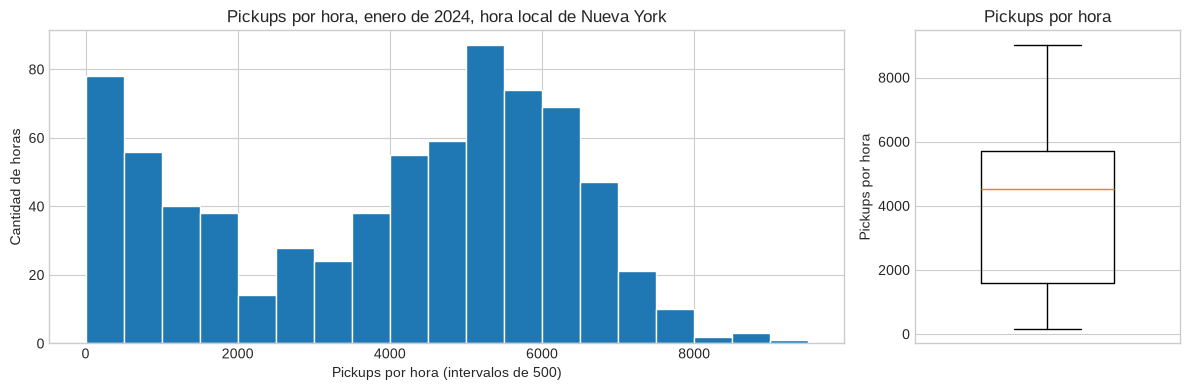

In [28]:
def ancho_freedman_diaconis(serie):
    s = serie.dropna()
    return 2 * (s.quantile(0.75) - s.quantile(0.25)) / len(s) ** (1 / 3)


ancho_pickups = 500
print("Ancho sugerido por Freedman-Diaconis:", round(ancho_freedman_diaconis(por_hora["pickups"]), 1))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [3, 1]})
bordes = np.arange(0, por_hora["pickups"].max() + ancho_pickups, ancho_pickups)
ejes[0].hist(por_hora["pickups"], bins=bordes, color="#1f77b4", edgecolor="white")
ejes[0].set(
    title=f"Pickups por hora, {periodo_tp}",
    xlabel=f"Pickups por hora (intervalos de {ancho_pickups})",
    ylabel="Cantidad de horas",
)
ejes[1].boxplot(por_hora["pickups"], widths=0.5)
ejes[1].set(title="Pickups por hora", ylabel="Pickups por hora", xticks=[])
plt.tight_layout()
plt.show()


**Qué comparación facilita:** muestra cuántas horas caen en cada nivel de actividad.

La distribución tiene dos grupos: el 28,5 % de las horas tiene menos de 2.000 pickups y el 52,6 % está entre 4.000 y 7.000. Por eso la media (3.933) queda por debajo de la mediana (4.519), y un único "valor típico" describe mal esta variable. El IQR es 4.127 y el desvío estándar es 2.276.

**Ancho del intervalo.** Freedman-Diaconis sugiere cerca de 900. Esa regla parte de la dispersión global, y acá la dispersión es alta justamente porque hay dos grupos. Se eligió 500 porque deja ver el valle entre ellos. La caja no muestra esa forma: es una vista complementaria para ubicar cuartiles y extremos.


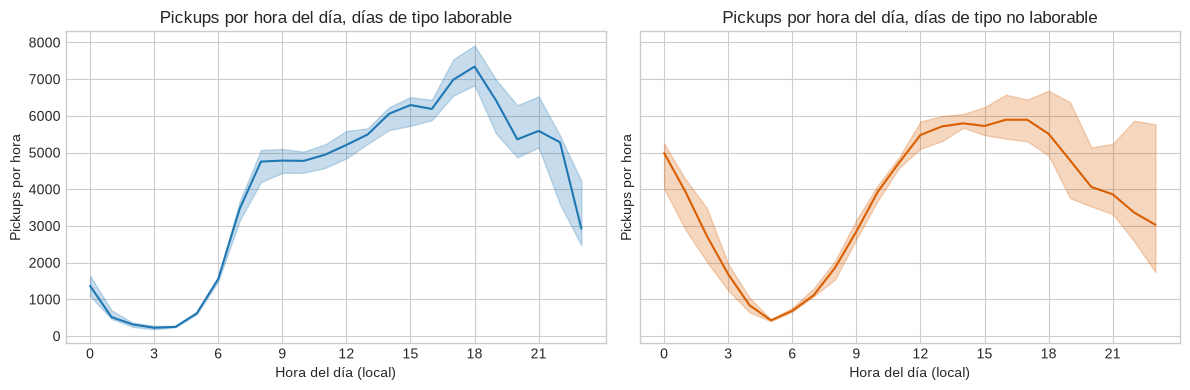

Días por tipo: {'laborable': 21, 'no laborable': 10}


In [29]:
perfil_pickups = (
    por_hora.groupby(["tipo_dia", "hora_dia"])["pickups"]
    .quantile([0.25, 0.5, 0.75])
    .unstack()
)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for eje, (tipo, color) in zip(ejes, [("laborable", "#1f77b4"), ("no laborable", "#d95f02")]):
    datos_tipo = perfil_pickups.loc[tipo]
    eje.plot(datos_tipo.index, datos_tipo[0.5], color=color)
    eje.fill_between(datos_tipo.index, datos_tipo[0.25], datos_tipo[0.75], color=color, alpha=0.25)
    eje.set(
        title=f"Pickups por hora del día, días de tipo {tipo}",
        xlabel="Hora del día (local)",
        ylabel="Pickups por hora",
        xticks=range(0, 24, 3),
    )
plt.tight_layout()
plt.show()
print("Días por tipo:", por_hora.groupby("tipo_dia")["fecha"].nunique().to_dict())


**Qué comparación facilita:** compara el ciclo diario entre días laborables y no laborables. La línea es la mediana y la banda va de Q1 a Q3.

Los dos grupos de pickups se corresponden con horas del día distintas. En los 21 días laborables, la mediana cae a 227 a las 03:00, llega a 4.754 a las 08:00 y alcanza 7.342 a las 18:00. En los 10 días no laborables (fines de semana, 1 y 15 de enero) arranca alta a medianoche (4.988), baja a 429 a las 05:00 y se mantiene cerca de 5.800 a la tarde. La banda se abre de noche en los días no laborables: ese grupo mezcla noches que no se parecen entre sí, como sábados y domingos.


### 6.3. Distribución de `humedad_relativa`

Ancho sugerido por Freedman-Diaconis: 6.8


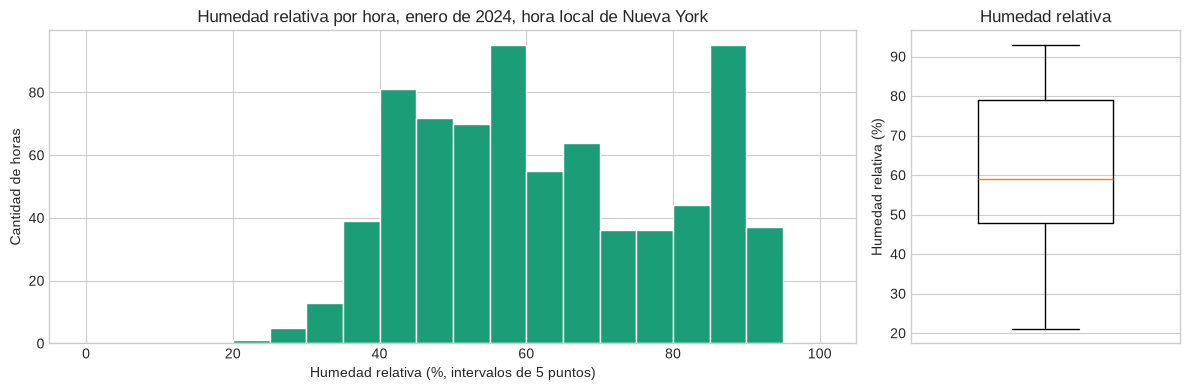

In [30]:
ancho_humedad = 5
print("Ancho sugerido por Freedman-Diaconis:", round(ancho_freedman_diaconis(por_hora["humedad_relativa"]), 1))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [3, 1]})
ejes[0].hist(
    por_hora["humedad_relativa"].dropna(),
    bins=np.arange(0, 100 + ancho_humedad, ancho_humedad),
    color="#1b9e77",
    edgecolor="white",
)
ejes[0].set(
    title=f"Humedad relativa por hora, {periodo_tp}",
    xlabel=f"Humedad relativa (%, intervalos de {ancho_humedad} puntos)",
    ylabel="Cantidad de horas",
)
ejes[1].boxplot(por_hora["humedad_relativa"].dropna(), widths=0.5)
ejes[1].set(title="Humedad relativa", ylabel="Humedad relativa (%)", xticks=[])
plt.tight_layout()
plt.show()


**Qué comparación facilita:** muestra cuántas horas caen en cada nivel de humedad.

La mediana es 59 %, la media 62,3 %, el IQR 31 puntos y el desvío 17,5 puntos. No hay un único pico: muchas horas están entre 40 % y 60 %, y aparece otro grupo entre 85 % y 90 %. La caja se ve simétrica y no muestra ese segundo grupo.

**Ancho del intervalo.** Freedman-Diaconis sugiere 6,8 puntos. Se redondeó a 5 porque es fácil de leer en porcentaje y conserva la forma de la distribución.


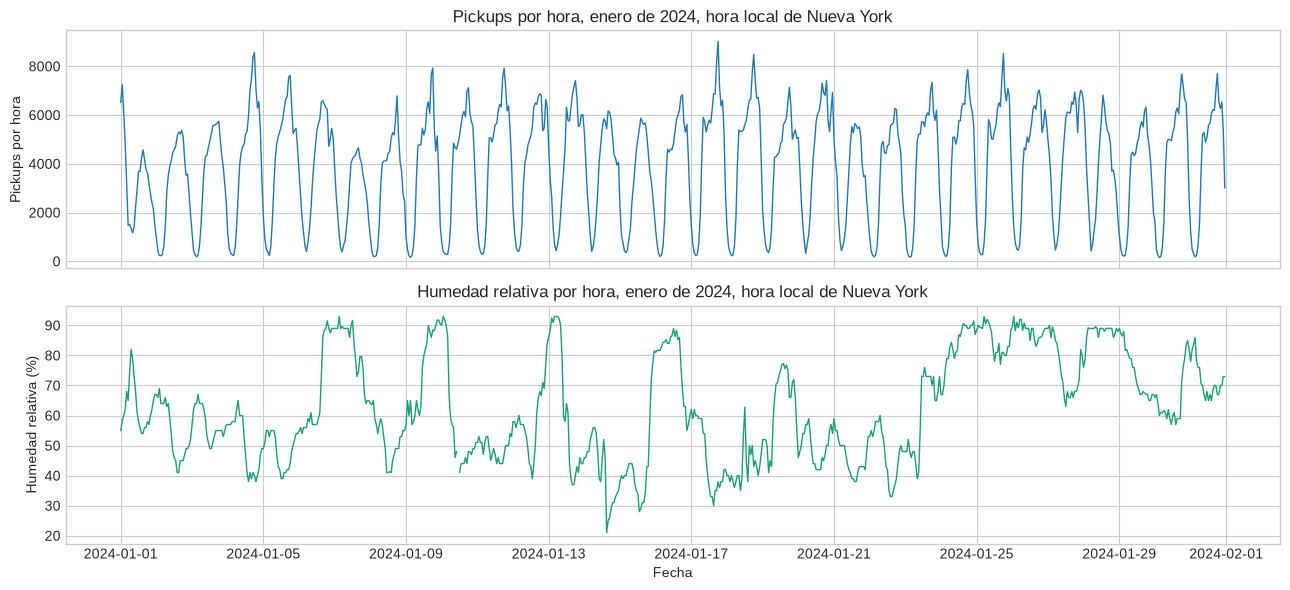

Mediana de humedad por franja:


,count,mean,std,min,25%,50%,75%,max
franja,,,,,,,,
00-05,186.0,65.6,16.5,36.0,54.0,60.0,82.8,93.0
06-11,185.0,63.3,16.3,35.0,51.0,59.0,79.0,93.0
12-17,186.0,58.3,19.2,21.0,42.0,55.5,75.4,91.7
18-23,186.0,62.2,17.3,29.0,48.0,60.0,76.8,91.8


Rango de la mediana por hora del día: 51.0 a 65.0


In [31]:
serie = por_hora.set_index("pickup_hora").reindex(horas_esperadas)

fig, ejes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ejes[0].plot(serie.index, serie["pickups"], color="#1f77b4", linewidth=1)
ejes[0].set(title=f"Pickups por hora, {periodo_tp}", ylabel="Pickups por hora")
ejes[1].plot(serie.index, serie["humedad_relativa"], color="#1b9e77", linewidth=1)
ejes[1].set(
    title=f"Humedad relativa por hora, {periodo_tp}",
    xlabel="Fecha",
    ylabel="Humedad relativa (%)",
)
plt.tight_layout()
plt.show()

perfil_humedad = por_hora.groupby("hora_dia")["humedad_relativa"].median()
print("Mediana de humedad por franja:")
display(por_hora.groupby("franja", observed=True)["humedad_relativa"].describe().round(1))
print("Rango de la mediana por hora del día:", perfil_humedad.min(), "a", perfil_humedad.max())


**Qué comparación facilita:** muestra las dos variables sobre el mismo eje de tiempo, sin rellenar huecos.

Las dos series cambian a ritmos distintos. Los pickups repiten un ciclo diario muy marcado durante todo el mes. La humedad se mueve sobre todo por episodios de varios días: hay periodos con muchas horas sobre 80 % alrededor del 6 y 7, del 9, del 16 y del 24 al 28 de enero, y un mínimo de 21 % el 14 de enero a las 15:00. También tiene un ciclo diario, pero chico: la mediana por hora del día va de 51 % a 65 %, mientras que la mediana por fecha va de 40 % a 89 %.


## 7. Casos potencialmente anómalos

**Regla 1:** Tukey global, fuera de `[Q1 - 1.5 IQR, Q3 + 1.5 IQR]`, sobre cada variable.

**Regla 2:** Tukey sobre el desvío de los pickups respecto de la mediana de su combinación de tipo de día y hora del día.

Las dos reglas generan candidatos para revisar, no errores confirmados.

In [32]:
def limites_tukey(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


columnas_contexto = [
    "pickup_hora", "dia_semana", "tipo_dia", "pickups", "humedad_relativa",
    "temperatura_c", "viento", "visibilidad",
]

marcas = {}
for columna in ["pickups", "humedad_relativa"]:
    inferior, superior = limites_tukey(por_hora[columna].dropna())
    marca = por_hora[columna].notna() & ~por_hora[columna].between(inferior, superior)
    marcas[columna] = marca
    print(f"{columna}: límites [{inferior:.1f}, {superior:.1f}], casos señalados: {int(marca.sum())}")

esperado = por_hora.groupby(["tipo_dia", "hora_dia"])["pickups"].transform("median")
por_hora["desvio_pickups"] = por_hora["pickups"] - esperado
inferior, superior = limites_tukey(por_hora["desvio_pickups"])
marcas["desvio_pickups"] = ~por_hora["desvio_pickups"].between(inferior, superior)
print(f"desvio_pickups: límites [{inferior:.1f}, {superior:.1f}], casos señalados: {int(marcas['desvio_pickups'].sum())}")
pd.set_option("display.max_rows", 100)
display(
    por_hora.loc[marcas["desvio_pickups"], columnas_contexto + ["desvio_pickups"]]
    .sort_values("desvio_pickups")
    .round({"humedad_relativa": 1, "temperatura_c": 1, "viento": 1, "visibilidad": 1, "desvio_pickups": 1})
)

pickups: límites [-4598.2, 11909.8], casos señalados: 0
humedad_relativa: límites [1.5, 125.5], casos señalados: 0
desvio_pickups: límites [-1260.8, 1242.7], casos señalados: 87


,pickup_hora,dia_semana,tipo_dia,pickups,humedad_relativa,temperatura_c,viento,visibilidad,desvio_pickups
337,2024-01-15 01:00:00-05:00,Monday,no laborable,1067,40.0,-3.9,2.6,16.1,-2861.5
336,2024-01-15 00:00:00-05:00,Monday,no laborable,2206,38.0,-3.3,3.1,16.1,-2782.0
46,2024-01-02 22:00:00-05:00,Tuesday,laborable,2720,50.0,3.9,2.6,16.1,-2560.0
190,2024-01-08 22:00:00-05:00,Monday,laborable,2757,55.0,3.9,0.0,16.1,-2523.0
526,2024-01-22 22:00:00-05:00,Monday,laborable,2800,48.0,1.1,5.1,16.1,-2480.0
43,2024-01-02 19:00:00-05:00,Tuesday,laborable,4179,47.0,5.0,2.1,16.1,-2246.0
42,2024-01-02 18:00:00-05:00,Tuesday,laborable,5134,45.0,5.0,0.0,16.1,-2208.0
694,2024-01-29 22:00:00-05:00,Monday,laborable,3091,67.0,2.2,3.6,16.1,-2189.0
17,2024-01-01 17:00:00-05:00,Monday,no laborable,3762,56.0,6.1,2.1,16.1,-2130.5
70,2024-01-03 22:00:00-05:00,Wednesday,laborable,3178,55.0,4.4,3.6,16.1,-2102.0


In [33]:
print("Valores que violan el dominio:")
print("  humedad fuera de 0 a 100:", int((~por_hora["humedad_relativa"].dropna().between(0, 100)).sum()))
print("  pickups negativos:", int(por_hora["pickups"].lt(0).sum()))

casos_por_fecha = (
    por_hora.loc[marcas["desvio_pickups"]]
    .groupby(["fecha", "tipo_dia"])
    .agg(
        horas=("pickups", "size"),
        desvio_medio=("desvio_pickups", "mean"),
        humedad_media=("humedad_relativa", "mean"),
    )
    .round(1)
)
display(casos_por_fecha)

display(
    por_hora.loc[marcas["desvio_pickups"]]
    .assign(sentido=lambda t: np.where(t["desvio_pickups"] > 0, "por encima", "por debajo"))
    .groupby(["tipo_dia", "dia_semana", "sentido"])
    .size()
    .rename("horas")
    .reset_index()
)

alguna_marca = marcas["pickups"] | marcas["humedad_relativa"] | marcas["desvio_pickups"]
comparacion = pd.DataFrame(
    {
        "pickups, todas": resumen(por_hora["pickups"]),
        "pickups, sin señalados": resumen(por_hora.loc[~alguna_marca, "pickups"]),
        "humedad, todas": resumen(por_hora["humedad_relativa"]),
        "humedad, sin señalados": resumen(por_hora.loc[~alguna_marca, "humedad_relativa"]),
    }
).loc[["n", "media", "mediana", "desvío", "IQR"]]
display(comparacion.round(2))

Valores que violan el dominio:
  humedad fuera de 0 a 100: 0
  pickups negativos: 0


,,horas,desvio_medio,humedad_media
fecha,tipo_dia,,,
2024-01-01,no laborable,18,-458.5,60.5
2024-01-02,laborable,6,-2078.2,47.5
2024-01-03,laborable,5,-1629.8,54.6
2024-01-04,laborable,2,1351.0,40.0
2024-01-05,laborable,1,1711.0,54.0
2024-01-06,no laborable,4,1049.4,81.0
2024-01-07,no laborable,6,-1461.7,79.8
2024-01-08,laborable,3,-1921.7,52.3
2024-01-09,laborable,2,-1571.0,91.1


,tipo_dia,dia_semana,sentido,horas
0,laborable,Friday,por encima,6
1,laborable,Monday,por debajo,6
2,laborable,Thursday,por encima,7
3,laborable,Tuesday,por debajo,8
4,laborable,Tuesday,por encima,1
5,laborable,Wednesday,por debajo,5
6,laborable,Wednesday,por encima,1
7,no laborable,Monday,por debajo,16
8,no laborable,Monday,por encima,5
9,no laborable,Saturday,por debajo,1


,"pickups, todas","pickups, sin señalados","humedad, todas","humedad, sin señalados"
n,744.00,657.00,743.00,656.00
media,3932.93,3816.25,62.34,62.52
mediana,4519.00,4481.00,59.00,60.00
desvío,2275.77,2300.37,17.53,17.73
IQR,4127.00,4195.00,31.00,31.00



**Regla 1 (Tukey global).** No señala ningún caso en ninguna variable. Los límites son `[-4.598, 11.910]` para pickups y `[1,5, 125,5]` para humedad. No significa que no haya horas raras: el IQR es grande porque cada variable tiene dos grupos, y entonces los límites quedan fuera del rango observado. Los extremos son valores válidos: el máximo de pickups (9.027) cae el 17 de enero a las 18:00, en la hora pico, y el mínimo (152) el 30 de enero a las 03:00.

**Regla 2 (desvío respecto de su momento).** Señala 87 horas, el 11,7 % del mes. Ninguna viola el dominio de la variable. Se ven estos patrones:

| Patrón | Horas | Lectura posible |
|---|---:|---|
| Sábados por encima | 22 | La referencia mezcla sábados y domingos, y las noches de sábado son más activas. |
| Jueves y viernes por encima | 13 | La referencia "laborable" mezcla estas noches con las del comienzo de la semana. |
| Lunes a miércoles laborables por debajo | 19 | Es el mismo efecto al revés. Además, 6 de esas horas son del 2 de enero, justo después de Año Nuevo. |
| 1 de enero | 18 | Feriado: pickups altos de madrugada y bajos durante el día. |
| 15 de enero | 3 | Feriado: madrugada mucho más baja que la de otros días no laborables. |

La tabla no cubre 12 de las 87 horas. Por ejemplo, faltan 7 horas de domingo por debajo, 6 de ellas del 7 de enero. El detalle completo está en las tablas de arriba.

**Explicaciones alternativas.** Además del calendario, una hora señalada puede reflejar un evento puntual, un cambio en la oferta de taxis, el clima u otra condición que no está en estos datos.

**Decisión.** Se conservan las 87 horas. Ninguna viola el dominio, y la mayoría forma un patrón de calendario, no un error de registro. Excluirlas quitaría variación real. La regla resultó menos específica de lo esperado, porque dos tipos de día son pocos para describir la semana.

**Con y sin señalados.** La media de pickups pasa de 3.933 a 3.816 y la mediana de 4.519 a 4.481. La media de humedad pasa de 62,3 % a 62,5 %. Los cambios son chicos.


## 8. Relación entre las columnas

Las dos columnas son numéricas, así que corresponde la sección 8.1 de la consigna. Primero se mira el diagrama de dispersión y después los coeficientes.

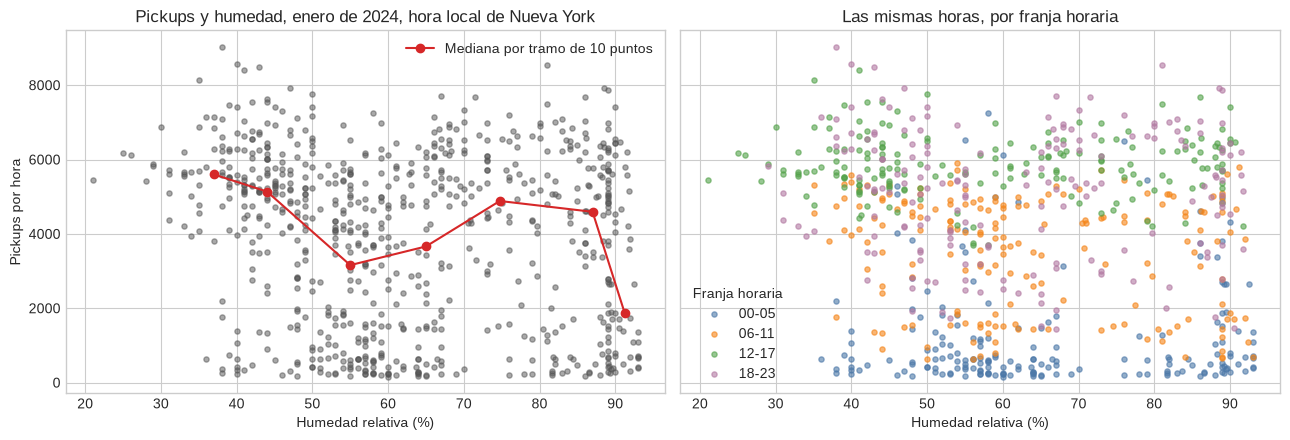

,humedad,pickups,horas
humedad_relativa,,,
"[30, 40)",37.0,5598.0,52
"[40, 50)",44.0,5138.0,153
"[50, 60)",55.0,3159.0,165
"[60, 70)",65.0,3662.0,119
"[70, 80)",74.8,4884.5,72
"[80, 90)",87.0,4593.0,139
"[90, 100)",91.2,1866.0,37


Porcentaje de horas de cada tramo, por franja horaria:


franja,00-05,06-11,12-17,18-23
humedad_relativa,,,,
"[30, 40)",9.6,15.4,53.8,21.2
"[40, 50)",14.4,23.5,32.7,29.4
"[50, 60)",37.0,29.7,12.1,21.2
"[60, 70)",29.4,24.4,19.3,26.9
"[70, 80)",12.5,29.2,31.9,26.4
"[80, 90)",28.1,23.7,23.0,25.2
"[90, 100)",40.5,24.3,13.5,21.6


In [34]:
colores_franja = {"00-05": "#4c78a8", "06-11": "#f58518", "12-17": "#54a24b", "18-23": "#b279a2"}

validas = por_hora.dropna(subset=["pickups", "humedad_relativa"]).copy()

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
ejes[0].scatter(validas["humedad_relativa"], validas["pickups"], s=14, alpha=0.5, color="#555555")
tramos = pd.cut(validas["humedad_relativa"], bins=np.arange(30, 111, 10), right=False)
medianas = validas.groupby(tramos, observed=True).agg(
    humedad=("humedad_relativa", "median"),
    pickups=("pickups", "median"),
    horas=("pickups", "size"),
)
ejes[0].plot(medianas["humedad"], medianas["pickups"], color="#d62728", marker="o", label="Mediana por tramo de 10 puntos")
ejes[0].legend()
ejes[0].set(
    title=f"Pickups y humedad, {periodo_tp}",
    xlabel="Humedad relativa (%)",
    ylabel="Pickups por hora",
)
for franja, color in colores_franja.items():
    grupo = validas[validas["franja"] == franja]
    ejes[1].scatter(grupo["humedad_relativa"], grupo["pickups"], s=14, alpha=0.6, color=color, label=franja)
ejes[1].legend(title="Franja horaria")
ejes[1].set(title="Las mismas horas, por franja horaria", xlabel="Humedad relativa (%)")
plt.tight_layout()
plt.show()
display(medianas.round(1))

# Qué horas del día caen en cada tramo de humedad.
print("Porcentaje de horas de cada tramo, por franja horaria:")
display((100 * pd.crosstab(tramos, validas["franja"], normalize="index")).round(1))


**Qué comparación facilita:** el panel izquierdo muestra la relación general, y el derecho separa las mismas horas por momento del día.

- **Dirección y forma:** no hay una tendencia clara. Con la misma humedad, los pickups van de pocos cientos a más de 7.000.
- **Curvatura:** la mediana por tramo no sube ni baja de forma sostenida. Baja de 5.598 a 3.159, vuelve a 4.885 y cae a 1.866 en el tramo de 90 % o más.
- **Grupos:** en el panel derecho las franjas forman capas horizontales. La madrugada queda abajo y la tarde arriba, en casi todo el rango de humedad.
- **Superposición:** la humedad tiene solo 130 valores distintos, y por eso se ven columnas verticales de puntos. Se usa transparencia para distinguirlos.

La tabla por franja muestra que las subidas y bajadas de la mediana acompañan qué horas caen en cada tramo. El tramo de 50 % a 60 % tiene 37 % de horas de madrugada y 12,1 % de tarde. El de 30 % a 40 % tiene 9,6 % de madrugada y 53,8 % de tarde. El tramo de 90 % o más tiene 37 horas de 9 fechas, con 40,5 % de madrugada. La caída final se asocia, al menos en parte, con esa composición, y no alcanza para hablar de un efecto de la humedad muy alta.


In [35]:
def correlaciones(tabla, x="humedad_relativa", y="pickups"):
    return {
        "n": len(tabla),
        "Pearson": tabla[x].corr(tabla[y]),
        "Spearman": tabla[x].rank().corr(tabla[y].rank()),
    }


filas_corr = {
    "Todas las horas válidas": correlaciones(validas),
    "Sin señalados en la sección 7": correlaciones(validas.loc[~alguna_marca.loc[validas.index]]),
}
display(pd.DataFrame(filas_corr).T.round(3))

# Puntos influyentes: cuánto cambia Pearson al quitar cada hora.
base_r = validas["humedad_relativa"].corr(validas["pickups"])
cambios = pd.Series(
    {
        i: validas.drop(index=i)["humedad_relativa"].corr(validas.drop(index=i)["pickups"]) - base_r
        for i in validas.index
    }
)
mas_influyentes = cambios.abs().sort_values(ascending=False).head(5).index
display(
    validas.loc[mas_influyentes, ["pickup_hora", "pickups", "humedad_relativa"]]
    .assign(cambio_en_r=cambios.loc[mas_influyentes].round(4))
)
print("Mayor cambio absoluto en Pearson al quitar una hora:", round(cambios.abs().max(), 4))

,n,Pearson,Spearman
Todas las horas válidas,743.0,-0.136,-0.139
Sin señalados en la sección 7,656.0,-0.140,-0.138


,pickup_hora,pickups,humedad_relativa,cambio_en_r
570,2024-01-24 18:00:00-05:00,7867,89.0,-0.0040
210,2024-01-09 18:00:00-05:00,7931,88.5,-0.0040
569,2024-01-24 17:00:00-05:00,7413,90.0,-0.0037
402,2024-01-17 18:00:00-05:00,9027,38.0,0.0036
412,2024-01-18 04:00:00-05:00,251,38.0,-0.0035


Mayor cambio absoluto en Pearson al quitar una hora: 0.004



Pearson da -0,136 y Spearman -0,139 sobre 743 horas. Los dos indican una asociación negativa débil. Pearson al cuadrado es cerca de 0,02: una recta se asocia con alrededor del 2 % de la variación de los pickups, y además la forma vista arriba no es una recta.

**Puntos influyentes:** no hay. Quitar cualquier hora cambia Pearson en 0,004 como máximo.


### 8.4. Dependencia y explicaciones alternativas

Las horas consecutivas no son observaciones independientes. Se mide esa dependencia con la autocorrelación de cada serie y con una aproximación del tamaño efectivo de muestra.

In [36]:
serie_completa = por_hora.set_index("pickup_hora").reindex(horas_esperadas)

autocorrelacion = pd.DataFrame(
    {
        columna: {
            f"{retardo} h": serie_completa[columna].autocorr(retardo)
            for retardo in (1, 24, 168)
        }
        for columna in ["pickups", "humedad_relativa"]
    }
)
display(autocorrelacion.round(3))

r1_x = autocorrelacion.loc["1 h", "pickups"]
r1_y = autocorrelacion.loc["1 h", "humedad_relativa"]
n_efectivo = len(validas) * (1 - r1_x * r1_y) / (1 + r1_x * r1_y)
print("Horas válidas:", len(validas))
print("Tamaño efectivo aproximado:", round(n_efectivo))

,pickups,humedad_relativa
1 h,0.937,0.975
24 h,0.860,0.262
168 h,0.934,-0.045


Horas válidas: 743
Tamaño efectivo aproximado: 33



Las dos series tienen mucha memoria de una hora a la siguiente (0,937 y 0,975), así que 743 horas no son 743 observaciones independientes. El tamaño efectivo aproximado es de unas 33 horas. Es solo un orden de magnitud: usa únicamente el retardo de 1 hora y supone una dependencia simple. Aun así, con un tamaño de ese orden, una correlación de 0,14 no se distingue con claridad de cero. Por eso este trabajo no informa valores p.

Los retardos largos también difieren. Los pickups se parecen a la misma hora del día anterior (0,860) y de la semana anterior (0,934). La humedad casi no (0,262 y -0,045): depende de episodios meteorológicos, no del calendario.

**Explicaciones alternativas para la asociación observada:**

- **Momento del día:** la tarde tiende a tener menos humedad y más pickups, y la madrugada lo contrario. Es la explicación que se pone a prueba en la sección 9.
- **Día de la semana y feriados:** cambian el nivel de actividad.
- **Otras condiciones meteorológicas:** temperatura, lluvia o visibilidad pueden moverse junto con la humedad. La lluvia no se puede evaluar aquí, porque `precipitacion_mm` está descartada.
- **Oferta de taxis y eventos:** no están medidos en estos datos.
- **Alcance de la medición:** hay una sola estación para toda la ciudad. Pasar a una fila por hora corrige la repetición entre zonas, pero no la dependencia temporal.


## 9. Análisis de sensibilidad

Se informan las tres alternativas declaradas en la sección 5. Pearson frente a Spearman y con o sin señalados ya están en la tabla de la sección 8. Falta la estratificación.

**Estratificación por hora del día:** dentro de una misma hora del día, las filas comparten el ciclo diario, y cada hora tiene hasta 31 observaciones.

**Comparación sin el ciclo:** a cada variable se le resta la mediana de su combinación de tipo de día y hora del día.

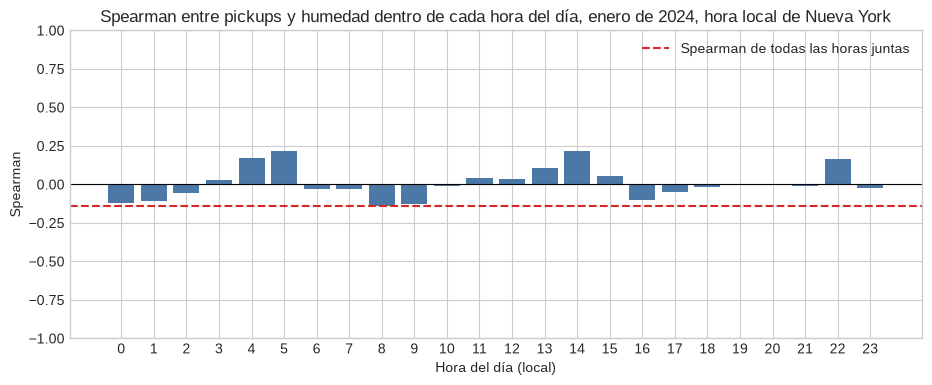

Mediana de los 24 Spearman: -0.01
Rango: -0.139 a 0.219
Horas con Spearman negativo: 14 de 24


hora_dia,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
n,31.000,31.000,31.000,31.000,31.000,31.000,31.000,31.000,31.000,31.000,31.000,30.000,31.000,31.000,31.000,31.000,31.000,31.000,31.000,31.000,31.000,31.000,31.000,31.000
Pearson,0.025,0.019,0.064,0.071,0.143,0.013,-0.114,-0.129,-0.168,-0.172,-0.091,0.001,0.003,0.126,0.098,0.063,-0.117,-0.062,-0.027,0.021,0.022,0.075,0.173,0.047
Spearman,-0.124,-0.106,-0.057,0.027,0.170,0.218,-0.031,-0.031,-0.139,-0.126,-0.009,0.040,0.038,0.106,0.219,0.055,-0.103,-0.052,-0.017,0.005,-0.003,-0.010,0.165,-0.022


In [37]:
por_estrato = pd.DataFrame(
    {hora: correlaciones(grupo) for hora, grupo in validas.groupby("hora_dia")}
).T
por_estrato.index.name = "hora_dia"

fig, eje = plt.subplots(figsize=(11, 4))
eje.bar(por_estrato.index, por_estrato["Spearman"], color="#4c78a8")
eje.axhline(filas_corr["Todas las horas válidas"]["Spearman"], color="#d62728", linestyle="--", label="Spearman de todas las horas juntas")
eje.axhline(0, color="black", linewidth=0.8)
eje.legend()
eje.set(
    title=f"Spearman entre pickups y humedad dentro de cada hora del día, {periodo_tp}",
    xlabel="Hora del día (local)",
    ylabel="Spearman",
    xticks=range(0, 24),
    ylim=(-1, 1),
)
plt.show()

print("Mediana de los 24 Spearman:", round(por_estrato["Spearman"].median(), 3))
print("Rango:", round(por_estrato["Spearman"].min(), 3), "a", round(por_estrato["Spearman"].max(), 3))
print("Horas con Spearman negativo:", int(por_estrato["Spearman"].lt(0).sum()), "de 24")
display(por_estrato.round(3).T)

,n,Pearson,Spearman
Todas las horas,743.0,-0.136,-0.139
Sin señalados,656.0,-0.140,-0.138
Solo días laborables,503.0,-0.095,-0.096
Solo días no laborables,240.0,-0.227,-0.228
Sin ciclo diario,743.0,0.015,-0.025
Sin ciclo diario y sin señalados,656.0,-0.017,-0.037


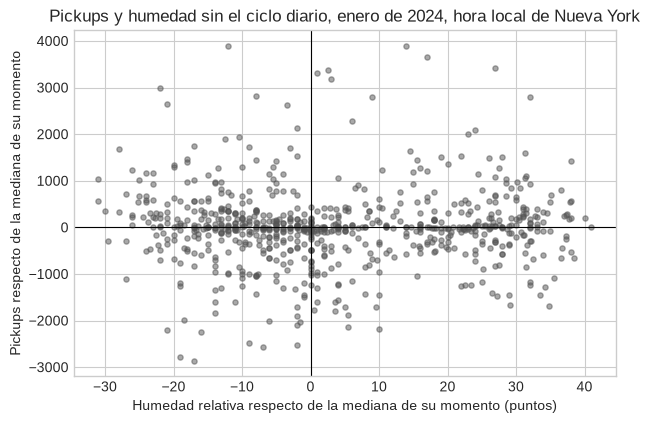

In [38]:
sin_ciclo = validas.copy()
claves = ["tipo_dia", "hora_dia"]
for columna in ["pickups", "humedad_relativa"]:
    sin_ciclo[columna] = sin_ciclo[columna] - sin_ciclo.groupby(claves)[columna].transform("median")

sensibilidad = pd.DataFrame(
    {
        "Todas las horas": correlaciones(validas),
        "Sin señalados": correlaciones(validas.loc[~alguna_marca.loc[validas.index]]),
        "Solo días laborables": correlaciones(validas[validas["tipo_dia"] == "laborable"]),
        "Solo días no laborables": correlaciones(validas[validas["tipo_dia"] == "no laborable"]),
        "Sin ciclo diario": correlaciones(sin_ciclo),
        "Sin ciclo diario y sin señalados": correlaciones(sin_ciclo.loc[~alguna_marca.loc[sin_ciclo.index]]),
    }
).T
display(sensibilidad.round(3))

fig, eje = plt.subplots(figsize=(7, 4.5))
eje.scatter(sin_ciclo["humedad_relativa"], sin_ciclo["pickups"], s=14, alpha=0.5, color="#555555")
eje.axhline(0, color="black", linewidth=0.8)
eje.axvline(0, color="black", linewidth=0.8)
eje.set(
    title=f"Pickups y humedad sin el ciclo diario, {periodo_tp}",
    xlabel="Humedad relativa respecto de la mediana de su momento (puntos)",
    ylabel="Pickups respecto de la mediana de su momento",
)
plt.show()


**1. Pearson frente a Spearman.** No cambia la conclusión: -0,136 y -0,139.

**2. Con y sin señalados.** Tampoco cambia: Pearson pasa de -0,136 a -0,140, y Spearman de -0,139 a -0,138.

**3. Estratificación y ciclo diario.** Esta alternativa sí cambia la conclusión:

- Dentro de cada hora del día, Spearman va de -0,139 a 0,219, con mediana -0,01. Hay 14 horas negativas y 10 positivas, sin un patrón claro. Cada valor usa unas 31 observaciones, así que estas diferencias son compatibles con ruido.
- Al quitar la mediana de cada combinación de tipo de día y hora del día, Pearson da 0,015 y Spearman -0,025. Si además se sacan las horas señaladas, dan -0,017 y -0,037.

La separación entre días laborables y no laborables se agregó como complemento y no estaba en la declaración previa. Da -0,096 y -0,228 en Spearman. Esas dos cifras todavía incluyen el ciclo diario, y el grupo no laborable tiene solo 10 días, por lo que no alcanzan para afirmar que la relación sea distinta entre ambos.

**Lectura conjunta.** La asociación débil no depende del coeficiente ni de las horas señaladas, pero sí de comparar horas de distintos momentos del día. Entre horas comparables, prácticamente desaparece.


## 10. Hallazgos finales


### Hallazgo 1: los pickups por hora forman dos grupos ligados al ciclo diario

- **Definición:** viajes Yellow Taxi válidos por hora local, sumados entre zonas, enero de 2024.
- **Observación:** el 28,5 % de las horas tiene menos de 2.000 pickups y el 52,6 % está entre 4.000 y 7.000 (histograma de la sección 6.2). En días laborables, la mediana va de 227 a las 03:00 a 7.342 a las 18:00. En días no laborables, la mediana es alta a medianoche (4.988) y se mantiene cerca de 5.800 a la tarde (perfil por hora del día).
- **Cobertura:** 744 de 744 horas, sin ceros ni faltantes, con 2.926.101 viajes válidos.
- **Interpretación:** una sola media describe mal a esta variable. Para compararla conviene fijar el momento del día.
- **Explicación alternativa:** el patrón puede reflejar la disponibilidad de taxis y los turnos de los conductores, además de las necesidades de viaje de las personas.
- **Límite:** son viajes realizados y reportados. No miden la demanda total ni las solicitudes no atendidas, y enero incluye dos feriados.
- **Siguiente comprobación:** repetir el perfil con más meses y separar sábados, domingos y feriados.

### Hallazgo 2: la humedad se mueve por episodios de varios días más que por la hora del día

- **Definición:** humedad relativa media por hora en la estación Central Park, enero de 2024.
- **Observación:** la mediana por fecha va de 40 % a 89 %, mientras que la mediana por hora del día va de 51 % a 65 % (serie de la sección 6.3). La autocorrelación es 0,975 a 1 hora, pero 0,262 a 24 horas y -0,045 a 168 horas (sección 8.4).
- **Cobertura:** 743 de 744 horas. Falta el 10 de enero a las 11:00, y no se imputó.
- **Interpretación:** en este mes, la fecha ordena la humedad más que la hora. El histograma tiene una zona de 40 % a 60 % y otro grupo entre 85 % y 90 %.
- **Explicación alternativa:** con solo un mes, unos pocos sistemas meteorológicos pueden definir toda la forma de la distribución.
- **Límite:** es una estación sola, y no representa la humedad de cada zona. Un mes no describe el comportamiento de otras estaciones del año.
- **Siguiente comprobación:** ampliar a más meses y contrastar con otra estación de la ciudad.

### Hallazgo 3: la asociación negativa débil entre pickups y humedad prácticamente desaparece al comparar horas del mismo momento del día

- **Definición:** relación entre pickups y humedad, una fila por hora, enero de 2024.
- **Observación:** con todas las horas, Spearman es -0,139 y Pearson -0,136 (sección 8). Dentro de cada hora del día, la mediana de Spearman es -0,01. Sin el ciclo diario, Spearman es -0,025 y Pearson 0,015 (sección 9).
- **Cobertura:** 743 horas válidas, con un tamaño efectivo aproximado de 33 por la dependencia temporal. Cada estrato horario tiene unas 31 observaciones.
- **Interpretación:** en estos datos, la asociación general se relaciona con el momento del día y no se observa una relación clara entre humedad y pickups en horas comparables. Esto no prueba que no exista ninguna relación: la potencia para detectar una relación chica es baja.
- **Explicación alternativa:** una relación real pero pequeña podría quedar oculta si afecta solo a algunas zonas, o si aparece junto con lluvia, que acá no se puede analizar.
- **Límite:** es un diseño observacional de un mes, con una estación. No permite afirmar efectos en ningún sentido. El resultado tampoco se puede trasladar a otros meses.
- **Siguiente comprobación:** repetir el análisis con seis meses, separar más tipos de día y, si se valida la precipitación, estudiar las horas de lluvia por separado.


## Límites y próximos pasos


**Límites**

- TLC registra viajes Yellow Taxi realizados, reportados y aprobados por los filtros de calidad. No incluye otras plataformas, solicitudes no atendidas ni la demanda total.
- La humedad viene de una sola estación y se aplica a toda la ciudad.
- Las horas consecutivas no son independientes, y por eso los coeficientes se leen de forma descriptiva.
- La referencia de dos tipos de día es simple: mezcla viernes con lunes y sábados con domingos. Esto se vio en la sección 7. Quitar el ciclo diario con esta referencia deja parte del patrón semanal adentro.
- Un mes de invierno, con dos feriados y pocos episodios húmedos, no permite generalizar.
- `precipitacion_mm` queda fuera del análisis, por lo que no se puede separar la humedad de la lluvia.

**Próximos pasos**

1. Repetir el análisis de enero a junio, como propone la actividad extra.
2. Usar un perfil por día de la semana y hora, con una categoría propia para feriados.
3. Pasar a la vista por zona si se consigue clima con detalle espacial.
4. Auditar `precipitacion_mm` para poder incluirla.
